# Real-Time ML: Resume Skills Audit (notebook edition)
**DSN AI Bootcamp 2026 · Real-Time Machine Learning: Building and Deploying an Inference System · Olalekan Akinsande**

Everything runs in this notebook:

| Part | What happens |
|---|---|
| 1. Setup | Install and import packages |
| 2. Build | Skills taxonomy, shared feature function, synthetic training data |
| 3. Train + deploy | Train the shortlisting model, save it as an artifact, load it into an inference engine |
| 4. Read documents | Read PDF / DOCX / TXT, extract skills, experience, education and location |
| 5. Skills audit | Score one resume against one job description, show gaps and the skills that would help most |
| 6. Upload | **Upload a resume and a job description**, then click *Run skills audit* |
| 7. Cohort audit | Audit many resumes against one job (a program-level view) |
| 8. Optional | Serve the same engine as a live API from inside the notebook |

**Quick start:** run *Kernel → Restart & Run All*, then scroll to Part 6 and upload your files.
Sample files are created in `sample_files/` so the notebook works even before you upload anything.

> Training data is synthetic. The model learns what (simulated) employers shortlist, so treat scores as a teaching demo, not a hiring decision.

> **Skills Audit Studio:** the reusable logic now lives in the `core/` package at the repo root. This notebook imports it and keeps only display and widget code.

## Part 1 · Setup

In [1]:
# Run once per environment (skip if already installed)
%pip install -q scikit-learn pandas numpy joblib matplotlib pypdf python-docx ipywidgets reportlab

Note: you may need to restart the kernel to use updated packages.


In [2]:
%matplotlib inline
import io, json, math, re, time, warnings
from datetime import date
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
SAMPLES = Path("sample_files"); SAMPLES.mkdir(exist_ok=True)
print("Ready. Artifacts ->", ART.resolve())

Ready. Artifacts -> C:\Users\DELL\Downloads\dsn speaker\artifacts


## Part 2 · Build
### 2.1 Skills taxonomy
One shared vocabulary. Resumes say *"MS Excel"*, *"MySQL"* or *"Kobo Toolbox"*; the model needs `excel`, `sql`, `survey_tools`.
In production this would be a maintained framework (ESCO, O*NET or a national skills framework).

In [3]:
from core.taxonomy import COURSES, IDX, PHRASES, SKILLS, SYNONYMS, course_for, pretty

print(f"{len(SKILLS)} skills, {len(PHRASES)} recognised phrases")

54 skills, 141 recognised phrases


### 2.2 One feature function, used in training **and** inference
If training and inference compute features differently, the model looks good offline and underperforms live (*training/serving skew*).

In [4]:
from core.features import EDU, EDU_LABEL, FEATURES, pair_features, skill_vector

### 2.3 Synthetic training data
Jobseekers, job posts and **employer shortlisting outcomes** (the label). Real projects would use historical application outcomes from a job platform or program.

In [5]:
from core.synthetic import EDU_LEVELS, ROLES, STATES, generate

t = time.perf_counter()
JOBS, CANDS, APPS = generate()
print(f"{len(JOBS):,} jobs | {len(CANDS):,} jobseekers | {len(APPS):,} applications | "
      f"shortlist rate {APPS.shortlisted.mean():.1%} | {time.perf_counter()-t:.1f}s")
APPS.head()

1,500 jobs | 4,000 jobseekers | 32,000 applications | shortlist rate 46.4% | 9.5s


,core_coverage,optional_coverage,n_core_missing,cosine_sim,exp_gap,exp_ok,edu_gap,location_ok,n_candidate_skills,candidate_id,job_id,signup_day,shortlisted,keyword_overlap
0,0.5,1.0,1,0.666667,-1,0,1,0,3,C0000,J0138,31,1,2
1,0.5,1.0,1,0.666667,0,1,1,0,3,C0000,J1191,31,1,2
2,0.5,0.0,1,0.333333,-2,0,1,0,3,C0000,J1295,31,1,1
3,0.5,0.5,1,0.577350,-2,0,1,1,3,C0000,J0269,31,0,2
4,0.5,0.0,1,0.333333,0,1,1,0,3,C0000,J1088,31,0,1


## Part 3 · Train, then "deploy"
Time-based split (train on older sign-ups, test on the newest), compare against plain keyword matching, then save the model as an **artifact**. The inference engine only ever loads the artifact, exactly like a production service.

In [6]:
X, y = APPS[FEATURES], APPS["shortlisted"].values
tr, te = APPS.signup_day < 48, APPS.signup_day >= 48

model = HistGradientBoostingClassifier(max_iter=250, learning_rate=0.05, random_state=0)
model.fit(X[tr], y[tr])

test = APPS[te].copy()
test["ml_score"] = model.predict_proba(X[te])[:, 1]
test["keyword_overlap"] += np.random.default_rng(0).random(len(test)) * 1e-3     # fair tie-break

def precision_at_k(df, col, k=3):
    top = df.sort_values(col, ascending=False).groupby("candidate_id").head(k)
    return top.groupby("candidate_id").shortlisted.mean().mean()

metrics = {
    "ROC-AUC (ML)": roc_auc_score(test.shortlisted, test.ml_score),
    "ROC-AUC (keyword)": roc_auc_score(test.shortlisted, test.keyword_overlap),
    "Precision@3 (ML)": precision_at_k(test, "ml_score"),
    "Precision@3 (keyword)": precision_at_k(test, "keyword_overlap"),
}
joblib.dump(model, ART / "model.joblib")
json.dump({"version": "skillaudit-v1", "features": FEATURES, "skills": SKILLS,
           "metrics": {k: round(float(v), 4) for k, v in metrics.items()}},
          open(ART / "model_meta.json", "w"), indent=2)
pd.Series(metrics).round(3).to_frame("value")

  File "C:\Users\DELL\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\DELL\anaconda3\Lib\subprocess.py",

,value
ROC-AUC (ML),0.940
ROC-AUC (keyword),0.875
Precision@3 (ML),0.804
Precision@3 (keyword),0.767


In [7]:
from core.engine import InferenceEngine

ENGINE = InferenceEngine(ART)
print("Engine loaded:", ENGINE.meta["version"], ENGINE.meta["metrics"])

Engine loaded: skillaudit-v1 {'ROC-AUC (ML)': 0.9396, 'ROC-AUC (keyword)': 0.8747, 'Precision@3 (ML)': 0.8041, 'Precision@3 (keyword)': 0.7675}


## Part 4 · Read documents and extract a profile
Supports **PDF, DOCX and TXT**. Scanned PDFs (images) have no text layer and need OCR first.

In [8]:
from core.documents import read_document, read_path

In [9]:
from core.parsing import NG_STATES, find_education, find_skills, find_state, split_sections

In [10]:
from core.parsing import parse_job, parse_resume

## Part 5 · The skills audit
One call: parse both documents → build features → score with the deployed model → explain gaps → rank the skills that would raise the score most.

In [11]:
from core.engine import skill_audit as core_skill_audit
from core.engine import verdict as verdict_label

VERDICT_COLOURS = {"Strong match": "#0B8457", "Moderate match": "#E59E00", "Weak match": "#E30613"}


def verdict(score):
    # core returns only the label; colours are a display concern, so they live in the notebook
    label = verdict_label(score)
    return label, VERDICT_COLOURS[label]


def skill_audit(resume_text, jd_text, state_override=None, resume_name="resume", show=True):
    report = core_skill_audit(ENGINE, resume_text, jd_text, state_override, resume_name)
    if show:
        render_report(report)
    return report

In [12]:
def render_report(r):
    v, colour = verdict(r["match_score"])
    tick = lambda ok: "✅" if ok else "❌"
    rows = "".join(
        f"<tr><td>{pretty(q['skill'])}</td><td>{q['type']}</td><td>{tick(q['status']=='Has')} {q['status']}</td>"
        f"<td style='color:#5F6B66'>{q['evidence']}</td></tr>" for q in r["requirements"])
    ck = r["checks"]
    checks = "".join(
        f"<tr><td>{k.title()}</td><td>{EDU_LABEL.get(c['candidate'], c['candidate']) if k=='education' else c['candidate']}</td>"
        f"<td>{EDU_LABEL.get(c['required'], c['required']) if k=='education' else c['required']}</td>"
        f"<td>{tick(c['ok'])}</td><td style='color:#5F6B66'>{c['note']}</td></tr>" for k, c in ck.items())
    pri = "".join(f"<tr><td>{pretty(p['skill'])}</td><td>+{p['lift']*100:.0f} pts</td><td>{p['score_after']*100:.0f}%</td>"
                  f"<td>{p['course']}</td></tr>" for p in r["priority_skills"]) or "<tr><td colspan=4>No single missing skill changes the score much.</td></tr>"
    unk = ", ".join(r["unrecognised_skills"]) or "none"
    extra = ", ".join(pretty(s) for s in r["extra_skills"]) or "none"
    tbl = "style='border-collapse:collapse;width:100%;font-size:13px' border='1' cellpadding='5'"
    html = f'''
    <div style="font-family:Segoe UI,Arial;border:1px solid #D9E3DD;border-radius:8px;padding:16px;max-width:900px">
      <div style="font-size:12px;color:#0B8457;font-weight:bold;letter-spacing:1px">SKILLS AUDIT</div>
      <div style="font-size:20px;font-weight:bold">{r['candidate_name']} → {r['job_title']}</div>
      <div style="margin:10px 0;display:flex;gap:24px;align-items:center">
        <div style="font-size:40px;font-weight:bold;color:{colour}">{r['match_score']*100:.0f}%</div>
        <div><b style="color:{colour}">{v}</b><br><span style="color:#5F6B66;font-size:12px">
          Model shortlist likelihood · keyword overlap {r['keyword_overlap']*100:.0f}% ·
          {r['latency_ms']} ms · {r['model_version']}</span></div></div>
      <h4>Skills required by the job</h4><table {tbl}><tr style="background:#EEF6F1"><th>Skill</th><th>Type</th><th>Status</th><th>Found as</th></tr>{rows}</table>
      <h4>Experience, education, location</h4><table {tbl}><tr style="background:#EEF6F1"><th>Check</th><th>Resume</th><th>Job</th><th>OK</th><th>Note</th></tr>{checks}</table>
      <h4>Skills that would raise the score most</h4><table {tbl}><tr style="background:#EEF6F1"><th>Skill</th><th>Lift</th><th>Score after</th><th>Suggested course</th></tr>{pri}</table>
      <p style="font-size:13px"><b>Other skills on the resume:</b> {extra}<br>
      <b>Listed but not recognised by the taxonomy:</b> {unk}</p>
    </div>'''
    display(HTML(html))
    if r["priority_skills"]:
        p = r["priority_skills"][::-1]
        fig, ax = plt.subplots(figsize=(7, 0.45 * len(p) + 1))
        ax.barh(["Today"] + [f"+ {pretty(x['skill'])}" for x in p],
                [r["match_score"]] + [x["score_after"] for x in p],
                color=["#B9C7BF"] + ["#0B8457"] * len(p))
        for i, val in enumerate([r["match_score"]] + [x["score_after"] for x in p]):
            ax.text(val + 0.01, i, f"{val:.0%}", va="center", fontsize=9)
        ax.set_xlim(0, 1); ax.set_xlabel("Shortlist likelihood"); ax.set_title("Skills diagnosis: score after adding one skill", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()

def export_markdown(r, path):
    lines = [f"# Skills audit: {r['candidate_name']} → {r['job_title']}", "",
             f"**Match score:** {r['match_score']*100:.0f}% ({r['verdict']}) · keyword overlap {r['keyword_overlap']*100:.0f}%", "",
             "| Skill | Type | Status | Found as |", "|---|---|---|---|"]
    lines += [f"| {pretty(q['skill'])} | {q['type']} | {q['status']} | {q['evidence']} |" for q in r["requirements"]]
    lines += ["", "| Check | Resume | Job | OK |", "|---|---|---|---|"]
    lines += [f"| {k} | {c['candidate']} | {c['required']} | {'Yes' if c['ok'] else 'No'} |" for k, c in r["checks"].items()]
    lines += ["", "## Priority skills", "| Skill | Lift | Course |", "|---|---|---|"]
    lines += [f"| {pretty(p['skill'])} | +{p['lift']*100:.0f} pts | {p['course']} |" for p in r["priority_skills"]]
    lines += ["", f"Unrecognised skills: {', '.join(r['unrecognised_skills']) or 'none'}"]
    Path(path).write_text("\n".join(lines), encoding="utf-8")
    return path

### 5.1 Sample files
Creates a sample job description (PDF) and four sample resumes (DOCX, PDF, TXT) so you can test without your own files.

In [13]:
SAMPLE_JD = '''Data Analyst - Youth Employment Programme
Location: Lagos (hybrid)

About the role
You will analyse programme data on young people's training and job outcomes and turn it into insight for partners.

Requirements
- Bachelor's degree or HND in Statistics, Economics, Computer Science or related field
- 2+ years of experience in a data role
- Strong SQL and Microsoft Excel (pivot tables, lookups)
- Data analysis of survey and administrative data
- Python (pandas) for data cleaning

Nice to have
- Power BI dashboards
- Statistics (regression, sampling)
- Monitoring and evaluation experience
- Excellent communication and report writing
'''
RESUMES = {
"amina_bello.docx": '''Amina Bello
Ikeja, Lagos | amina.bello@email.com

Summary
Data analyst with 3 years of experience turning survey data into dashboards for NGOs.

Work Experience
Data Analyst, Lagos Skills Hub | 2023 - Present
- Analysed survey data for 12,000 trainees using MySQL and MS Excel pivot tables
- Built Tableau dashboards for partner reporting
Data Officer, Bright Futures NGO | 2021 - 2023
- Collected field data with Kobo Toolbox; wrote monthly M&E reports

Education
B.Sc. Economics, University of Lagos, 2020

Skills
MS Excel, MySQL, Tableau, Kobo Toolbox, Report writing, Communication, Prompt engineering
''',
"tunde_okafor.pdf": '''Tunde Okafor
Abuja, FCT

Profile
Junior data scientist, 2 years experience building predictive models.

Experience
Data Scientist Intern, FinServe Ltd | 2024 - Present
Analytics Assistant, GovTech Lab | 2023 - 2024

Education
M.Sc. Statistics, University of Ibadan

Skills
Python, pandas, scikit-learn, SQL, Statistics, Power BI, Data analysis, Teamwork
''',
"chioma_eze.txt": '''Chioma Eze
Enugu

Profile
Monitoring and evaluation assistant with 1 year of experience in community health programmes.

Experience
M&E Assistant, HealthReach | 2025 - Present

Education
HND Statistics, Institute of Management and Technology

Skills
Excel, Data entry, ODK, Report writing, Communication, Community health
''',
"musa_ibrahim.txt": '''Musa Ibrahim
Kano

Experience
Solar Installer, SunPower Kano | 2022 - Present

Education
NABTEB Electrical Installation certificate

Skills
Solar installation, Electrical wiring, Customer service, Driving
''',
}

def write_pdf(path, text):
    from reportlab.lib.pagesizes import A4
    from reportlab.pdfgen import canvas
    c = canvas.Canvas(str(path), pagesize=A4); y = 800
    for line in text.splitlines():
        c.setFont("Helvetica", 10); c.drawString(50, y, line); y -= 15
    c.save()

def write_docx(path, text):
    import docx
    d = docx.Document()
    for line in text.splitlines():
        d.add_paragraph(line)
    d.save(str(path))

write_pdf(SAMPLES / "job_data_analyst.pdf", SAMPLE_JD)
(SAMPLES / "resumes").mkdir(exist_ok=True)
for fname, text in RESUMES.items():
    p = SAMPLES / "resumes" / fname
    {".pdf": write_pdf, ".docx": write_docx}.get(p.suffix, lambda pp, tt: pp.write_text(tt, encoding="utf-8"))(p, text)
print(sorted(str(p) for p in SAMPLES.rglob("*.*")))

['sample_files\\job_data_analyst.pdf', 'sample_files\\resumes\\amina_bello.docx', 'sample_files\\resumes\\chioma_eze.txt', 'sample_files\\resumes\\musa_ibrahim.txt', 'sample_files\\resumes\\tunde_okafor.pdf']


Skill,Type,Status,Found as
Data analysis,Required,✅ Has,data analyst
Excel,Required,✅ Has,pivot tables
Python,Required,❌ Missing,
SQL,Required,✅ Has,mysql
Communication,Nice to have,✅ Has,communication
Data visualisation,Nice to have,✅ Has,dashboards
English / report writing,Nice to have,✅ Has,report writing
M&E,Nice to have,✅ Has,m&e
Power BI,Nice to have,❌ Missing,
Statistics,Nice to have,❌ Missing,


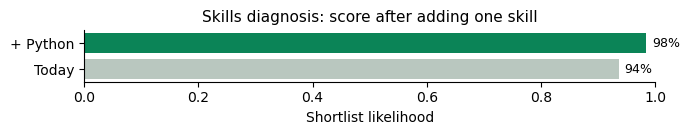

In [14]:
# Try it on the sample files (no upload needed)
jd_text = read_path(SAMPLES / "job_data_analyst.pdf")
report = skill_audit(read_path(SAMPLES / "resumes" / "amina_bello.docx"), jd_text, resume_name="amina_bello.docx")

## Part 6 · Upload a resume and a job description
1. Click **Upload resume(s)**: PDF, DOCX or TXT (you can select several).
2. Click **Upload job description**, **or** paste the job description into the box.
3. Optional: set the candidate's state if the resume doesn't show it.
4. Click **Run skills audit**.

> If the buttons don't appear (e.g. some VS Code or Colab setups), use the *file path* cell below instead.

In [16]:
try:
    import ipywidgets as w
except ImportError:
    w = None
    print("ipywidgets not installed: run  %pip install ipywidgets  and restart the kernel, or use the file-path cell below.")

def _uploaded(up):
    # works with ipywidgets 7 (dict) and 8 (tuple of dicts)
    v = up.value
    if isinstance(v, dict):
        return [(k, bytes(x["content"])) for k, x in v.items()]
    return [(x["name"], bytes(x["content"])) for x in v]

LAST_REPORTS = []
if w:
    resume_up = w.FileUpload(accept=".pdf,.docx,.txt", multiple=True, description="Upload resume(s)",
                             layout=w.Layout(width="220px"))
    jd_up = w.FileUpload(accept=".pdf,.docx,.txt", multiple=False, description="Upload job description",
                         layout=w.Layout(width="220px"))
    jd_box = w.Textarea(placeholder="...or paste the job description here", layout=w.Layout(width="95%", height="120px"))
    state_dd = w.Dropdown(options=["(detect from resume)"] + NG_STATES, description="Candidate state:",
                          style={"description_width": "initial"})
    run_btn = w.Button(description="Run skills audit", button_style="success", icon="search")
    save_cb = w.Checkbox(value=True, description="Save reports to /reports")
    out = w.Output()

    def on_run(_):
        out.clear_output()
        with out:
            try:
                jd_files = _uploaded(jd_up)
                jd = read_document(*jd_files[0]) if jd_files else jd_box.value
                if len(jd.strip()) < 30:
                    print("Please upload or paste a job description."); return
                resumes = _uploaded(resume_up)
                if not resumes:
                    print("Please upload at least one resume."); return
                state = None if state_dd.value.startswith("(") else state_dd.value
                LAST_REPORTS.clear()
                for name, data in resumes:
                    r = skill_audit(read_document(name, data), jd, state_override=state, resume_name=name)
                    LAST_REPORTS.append(r)
                    if save_cb.value:
                        Path("reports").mkdir(exist_ok=True)
                        print("Saved:", export_markdown(r, Path("reports") / f"audit_{Path(name).stem}.md"))
                if len(LAST_REPORTS) > 1:
                    display(Markdown("### Cohort summary")); display(cohort_table(LAST_REPORTS))
            except Exception as e:
                print("⚠️", e)

    run_btn.on_click(on_run)
    display(w.VBox([w.HBox([resume_up, jd_up, state_dd]), jd_box, w.HBox([run_btn, save_cb]), out]))

In [ ]:
# # Alternative without widgets: point to files on disk
# RESUME_PATH = SAMPLES / "resumes" / "tunde_okafor.pdf"     # <- change to your resume file
# JD_PATH = SAMPLES / "job_data_analyst.pdf"                  # <- change to your job description file
# STATE = None                                                # e.g. "Lagos" to override detection

# report = skill_audit(read_path(RESUME_PATH), read_path(JD_PATH), state_override=STATE, resume_name=Path(RESUME_PATH).name)

## Part 7 · Cohort skills audit
The same engine, run over a folder of resumes: who is closest to the job, and which gaps are most common (what training to fund).

,resume,candidate,match_%,verdict,missing_required,top_priority_skill
0,amina_bello.docx,Amina Bello,94,Strong match,Python,Python
1,tunde_okafor.pdf,Tunde Okafor,61,Moderate match,Excel,Excel
2,chioma_eze.txt,Chioma Eze,8,Weak match,"Data analysis, Python, SQL",Data analysis
3,musa_ibrahim.txt,Musa Ibrahim,4,Weak match,"Data analysis, Excel, Python, SQL",Data analysis


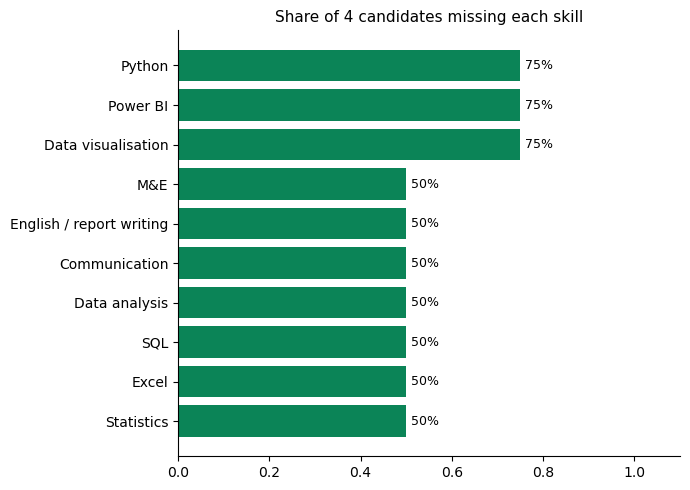

Skills on resumes the taxonomy doesn't recognise yet (possible emerging skills): {'Prompt engineering': np.int64(1)}


In [17]:
def cohort_table(reports):
    return pd.DataFrame([{"resume": r["resume"], "candidate": r["candidate_name"], "match_%": round(r["match_score"] * 100),
                          "verdict": r["verdict"], "missing_required": ", ".join(pretty(s) for s in r["missing_core"]) or "-",
                          "top_priority_skill": pretty(r["priority_skills"][0]["skill"]) if r["priority_skills"] else "-"}
                         for r in reports]).sort_values("match_%", ascending=False).reset_index(drop=True)

def audit_folder(jd_text, folder, state_override=None):
    files = [p for p in Path(folder).iterdir() if p.suffix.lower() in (".pdf", ".docx", ".txt")]
    reports = [skill_audit(read_path(p), jd_text, state_override, p.name, show=False) for p in files]
    display(cohort_table(reports))
    gaps = pd.Series([s for r in reports for s in r["missing_core"] + r["missing_optional"]]).value_counts()
    if len(gaps):
        share = (gaps / len(reports)).sort_values()
        fig, ax = plt.subplots(figsize=(7, 0.4 * len(share) + 1))
        ax.barh([pretty(s) for s in share.index], share.values, color="#0B8457")
        for i, v in enumerate(share.values): ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=9)
        ax.set_xlim(0, 1.1); ax.set_title(f"Share of {len(reports)} candidates missing each skill", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False); plt.tight_layout(); plt.show()
    unk = pd.Series([u for r in reports for u in r["unrecognised_skills"]]).value_counts()
    if len(unk):
        print("Skills on resumes the taxonomy doesn't recognise yet (possible emerging skills):", dict(unk))
    return reports

cohort = audit_folder(jd_text, SAMPLES / "resumes")

## Part 8 (optional) · Serve the same engine as a live API
Runs a FastAPI server **inside this notebook** (background thread), the "deploy" step from the talk. Needs `fastapi`, `uvicorn` and `httpx`.

In [20]:
#%pip install -q fastapi uvicorn httpx
import threading
from fastapi import FastAPI
from pydantic import BaseModel
import uvicorn

api = FastAPI(title="Skills Audit API", version=ENGINE.meta["version"])

class AuditRequest(BaseModel):
    resume_text: str
    jd_text: str
    state: str | None = None

@api.get("/health")
def health():
    return {"status": "ok", "model_version": ENGINE.meta["version"]}

@api.post("/skill-audit")
def api_audit(req: AuditRequest):
    return skill_audit(req.resume_text, req.jd_text, req.state, show=False)

PORT = 8765
server = uvicorn.Server(uvicorn.Config(api, host="127.0.0.1", port=PORT, log_level="warning"))
threading.Thread(target=server.run, daemon=True).start()
for _ in range(50):
    if server.started: break
    time.sleep(0.1)
print(f"API running: http://127.0.0.1:{PORT}/docs   (stop with: server.should_exit = True)")

Note: you may need to restart the kernel to use updated packages.
API running: http://127.0.0.1:8765/docs   (stop with: server.should_exit = True)


In [21]:
import httpx
body = {"resume_text": read_path(SAMPLES / "resumes" / "chioma_eze.txt"), "jd_text": jd_text}
lat = []
for _ in range(20):
    t = time.perf_counter(); resp = httpx.post(f"http://127.0.0.1:{PORT}/skill-audit", json=body, timeout=10)
    lat.append((time.perf_counter() - t) * 1000)
r = resp.json()
print(f"{r['candidate_name']} -> {r['job_title']}: {r['match_score']:.0%} ({r['verdict']})")
print(f"missing required: {r['missing_core']} | latency p50 {np.percentile(lat, 50):.1f} ms, max {max(lat):.1f} ms")

Chioma Eze -> Data Analyst - Youth Employment Programme: 8% (Weak match)
missing required: ['data_analysis', 'python', 'sql'] | latency p50 320.0 ms, max 400.5 ms


In [22]:
# Stop the API when you're done
server.should_exit = True